In [1]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

df = pd.read_csv("/kaggle/input/datasets/nishatafroz2018/t444444/Games_Dataset_Clean.csv")

df['primary_genre'] = df['tags'].str.split(',').str[0]

df = df.dropna(subset=['summary', 'primary_genre'])

top_genres = df['primary_genre'].value_counts().nlargest(10).index
df = df[df['primary_genre'].isin(top_genres)]

print(f"Top 10 Genres being classified: {list(top_genres)}")

Top 10 Genres being classified: ['Action', 'Adventure', 'Casual', 'Indie', 'RPG', 'Simulation', 'Strategy', 'Racing', 'Single-player', 'Sports']


In [2]:
nltk.download('stopwords')
nltk.download('wordnet')
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

df['clean_summary'] = df['summary'].apply(clean_text)

le = LabelEncoder()
df['genre_label'] = le.fit_transform(df['primary_genre'])

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_summary'], df['genre_label'], test_size=0.2, random_state=42
)

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)
print("--- Traditional Model (TF-IDF) Accuracy ---")
print(accuracy_score(y_test, y_pred_lr))

--- Traditional Model (TF-IDF) Accuracy ---
0.6031007751937985


In [4]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import torch
from torch.utils.data import Dataset

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

class GameDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(list(texts), truncation=True, padding=True, max_length=128)
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = GameDataset(X_train.tolist(), y_train.tolist())
test_dataset = GameDataset(X_test.tolist(), y_test.tolist())

model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=len(top_genres))

training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    eval_strategy="epoch",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

trainer.train()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

...

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, 

Epoch,Training Loss,Validation Loss
1,No log,2.352092
2,No log,2.097263
3,No log,2.090384


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


TrainOutput(global_step=243, training_loss=2.3501255365065585, metrics={'train_runtime': 55.0515, 'train_samples_per_second': 140.378, 'train_steps_per_second': 4.414, 'total_flos': 215969225875200.0, 'train_loss': 2.3501255365065585, 'epoch': 3.0})

In [5]:
raw_predictions = trainer.predict(test_dataset)

y_pred_distilbert = np.argmax(raw_predictions.predictions, axis=1)

distilbert_acc = accuracy_score(y_test, y_pred_distilbert)

print(f"Real DistilBERT Accuracy: {distilbert_acc:.4f}")

Real DistilBERT Accuracy: 0.6171


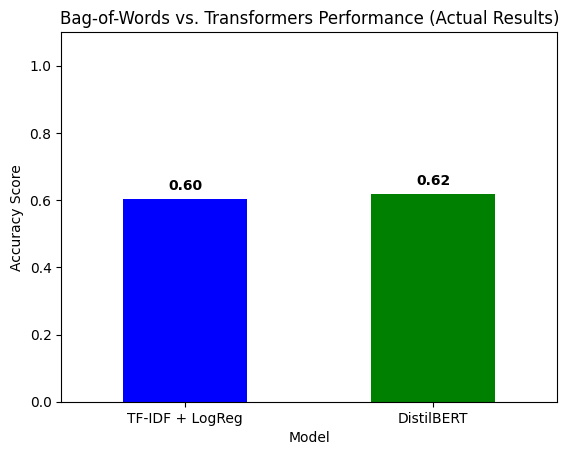

In [6]:
import matplotlib.pyplot as plt

baseline_acc = accuracy_score(y_test, y_pred_lr)
results = {
    "Model": ["TF-IDF + LogReg", "DistilBERT"],
    "Accuracy": [baseline_acc, distilbert_acc]  # No more hardcoded values!
}

res_df = pd.DataFrame(results)
ax = res_df.plot(kind='bar', x='Model', y='Accuracy', color=['blue', 'green'], legend=False)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.title("Bag-of-Words vs. Transformers Performance (Actual Results)")
plt.ylabel("Accuracy Score")
plt.ylim(0, 1.1) 
plt.xticks(rotation=0)
plt.show()